In [1]:
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
from Algos.AlgosPaper import NMPBB, QRPBB, AdaPGE1,AdaPGE2,AdaPGE3, NeNMF,ANPBB, EMPBB, EMPBBW
from NMF_ANLS import solve_NMF_ANLS, solve_NMF_EPMPBB, solve_NMF_NeNMF,\
        solve_NMF_ANLS2

In [2]:
from numba import njit
from statistics import mean, median
from scipy.interpolate import interp1d

# --- Helper functions (Compiled with Numba) ---
@njit(cache=True, fastmath=True)
def proj(X):
    return np.maximum(X, 0.0)

@njit(cache=True, fastmath=True)
def solve_W_NMPBB(V, H, W0, max_iter=1000, tol=1e-5):
    W = W0.copy()
    m, r = W.shape
    
    VHT = V @ H.T
    HHT = H @ H.T
    tr1 = np.sum(V * V)
    
    L = np.linalg.norm(HHT)
    if L == 0.0 or np.isnan(L) or np.isinf(L):
        L = 1.0
    
    alpha_max = 1e20
    alpha_min = 1e-20
    alpha_t = 1.0
    rho = 0.25
    eta0=.1
    gamma = 1e-4
    mu = 0.5
    c = 1e-4
    s = 1.7 
    
    S_val = 0.0
    f_Z_prev = 0.0
    # tol=1e-8
    iter=0
    for t in range(max_iter):
        # gradW = (W @ H - V) @ H.T
        gradW = W @ HHT - VHT
        iter=iter+1
        if np.linalg.norm(proj(W - gradW) - W) < tol or f_Z_prev > 3e4: # use this only for high order problems
        # if np.linalg.norm(proj(W - gradW) - W) < tol:
            break
            
        Z_t = proj(W - (1.0 / L) * gradW)
        gradZ = Z_t @ HHT - VHT
        # gradZ = (Z_t @ H - V) @ H.T
        f_Z = 0.5 * (tr1 - 2.0 * np.sum(Z_t * VHT) + np.sum((Z_t.T @ Z_t) * HHT))
        
        if t == 0:
            S_val = f_Z
        else:
            eta_t = (2.0 / np.pi) * np.arctan(abs(f_Z - f_Z_prev))
            S_val = f_Z + eta_t * (S_val - f_Z)
        f_Z_prev = f_Z
        
        # --- FIX: Replace boolean mask indexing with explicit loops ---
  # ------------------------------------------------------------
        # ACTIVE SET DIRECTION (Vectorized, Numba-safe)
        # ------------------------------------------------------------
        alpha_inv = 1.0/alpha_t
        
        # Boolean masks (Numba creates these efficiently)
        mask_active = Z_t <= alpha_inv * gradZ
        mask_L1 = mask_active & (gradZ >= c)
        mask_not_L1 = ~mask_L1
        
        # Generic projected BB step for free set / L2
        BB_step = proj(Z_t - alpha_t * gradZ) - Z_t
        
        # 1. Assign BB_step to not L1, and 0 to L1
        D_t = np.where(mask_not_L1, BB_step, 0.0)
        
        # 2. Overwrite L1^+ with -Z_t
        mask_L1_plus = mask_L1 & (Z_t != 0.0)
        D_t = np.where(mask_L1_plus, -Z_t, D_t)
        # ------------------------------------------------------------
        # Nonmonotone line search
        lambda_t = 1.0
        j=0.
        while True:
            W_candidate = Z_t + s * lambda_t * D_t
            f_Wcand = 0.5 * (tr1 - 2.0 * np.sum(W_candidate * VHT) + np.sum((W_candidate.T @ W_candidate) * HHT))
            S_candidate = f_Wcand + (0.5 if t == 0 else eta_t) * (S_val - f_Wcand)
            condition = np.sum(gradZ * D_t) + (mu / alpha_t) * np.sum(D_t * D_t)
            if S_candidate <= S_val + gamma * lambda_t * condition:
                break
            lambda_t *= rho
            j = j+1
            if lambda_t < 1e-20:
                break
        iter=iter+j    
        W_new = Z_t + s * lambda_t * D_t
        X_t = W_new - Z_t
        # Y_t = ((W_new @ H - V) @ H.T) - gradZ
        Y_t = (W_new @ HHT - VHT) - gradZ
        xy = np.sum(X_t * Y_t)
        if xy <= 0.0:
            alpha_t = alpha_max
        else:
            xx = np.sum(X_t * X_t)
            alpha_t = min(alpha_max, max(alpha_min, xx / xy))
            
        # W_new = np.where(np.isnan(W_new), 0.0, W_new)
        # W_new = np.where(np.isinf(W_new), 1e10, W_new)
        W = W_new
    return W, iter

Running 5 trials for each method...

Trials complete. Processing results...

              |      Time       |       Obj        |       Res        |       Proj       |      InIter      |               Cond               |  Theo Rate (q) 
Method        |      ----       |       ---        |       ---        |       ----       |      ------      |              -----               | -------------- 
              |       μ±σ       |       μ±σ        |       μ±σ        |       μ±σ        |       μ±σ        |               μ±σ                |       μ±σ      
NMPBB        | 3.7972 ± 4.6767 | 620063.5598 ± 8633.1116 | 0.2042 ± 0.0024 | 8088.4198 ± 120.1932 | 640.00 ± 0.00   | 3.03 x 10^{6} ± 2.92 x 10^{6} | 1.00   ± 0.00  
EPMPBB       | 50.7578 ± 6.3765 | 24182.7745 ± 1440.1281 | 0.0403 ± 0.0014 | 46.3311 ± 48.0696 | 8568.40 ± 1107.13 | 2.09 x 10^{6} ± 1.25 x 10^{6} | 1.00   ± 0.00  
EPMPBB-W     | 19.6851 ± 3.1028 | 23935.6997 ± 1306.0469 | 0.0401 ± 0.0013 | 70.2827 ± 63.5360 | 2954.80 ± 47

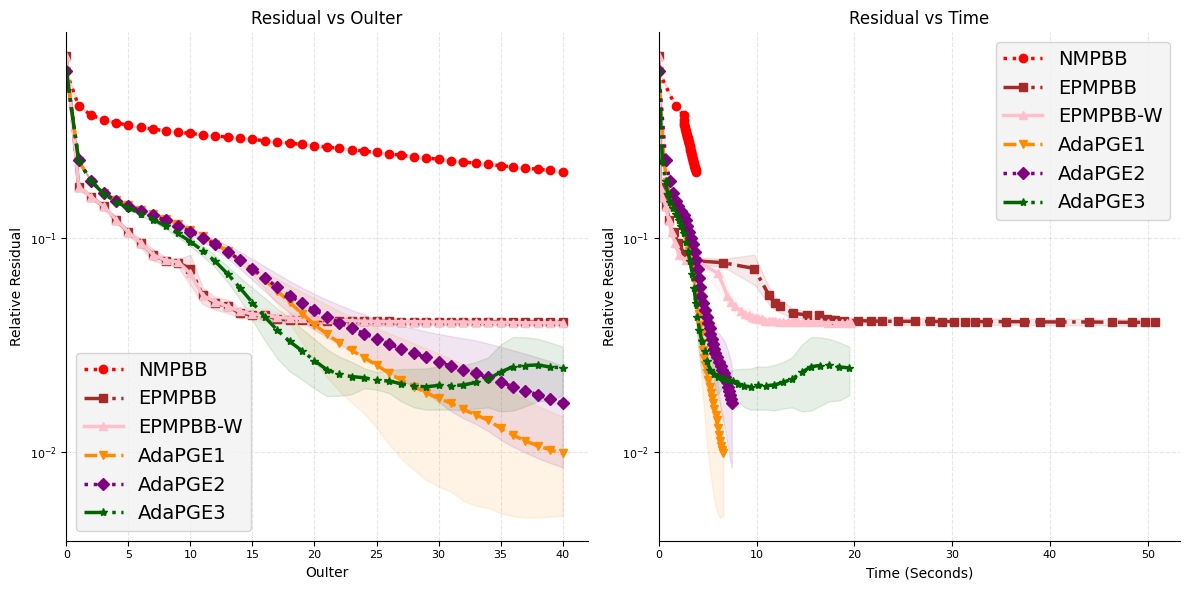

Running 5 trials for each method...

Trials complete. Processing results...

              |      Time       |       Obj        |       Res        |       Proj       |      InIter      |               Cond               |  Theo Rate (q) 
Method        |      ----       |       ---        |       ---        |       ----       |      ------      |              -----               | -------------- 
              |       μ±σ       |       μ±σ        |       μ±σ        |       μ±σ        |       μ±σ        |               μ±σ                |       μ±σ      
NMPBB        | 3.2027 ± 0.3164 | 2807166.2935 ± 23703.9441 | 0.2137 ± 0.0009 | 26861.2086 ± 155.0683 | 680.00 ± 0.00   | 6.96 x 10^{5} ± 5.99 x 10^{5} | 1.00   ± 0.00  
EPMPBB       | 91.5619 ± 27.8060 | 89595.6837 ± 6017.0607 | 0.0382 ± 0.0011 | 157.3306 ± 97.8316 | 7230.00 ± 2272.05 | 3.19 x 10^{6} ± 2.19 x 10^{6} | 1.00   ± 0.00  
EPMPBB-W     | 41.5173 ± 8.1232 | 89457.0090 ± 5974.8073 | 0.0381 ± 0.0011 | 103.1267 ± 79.7699 | 3285.6

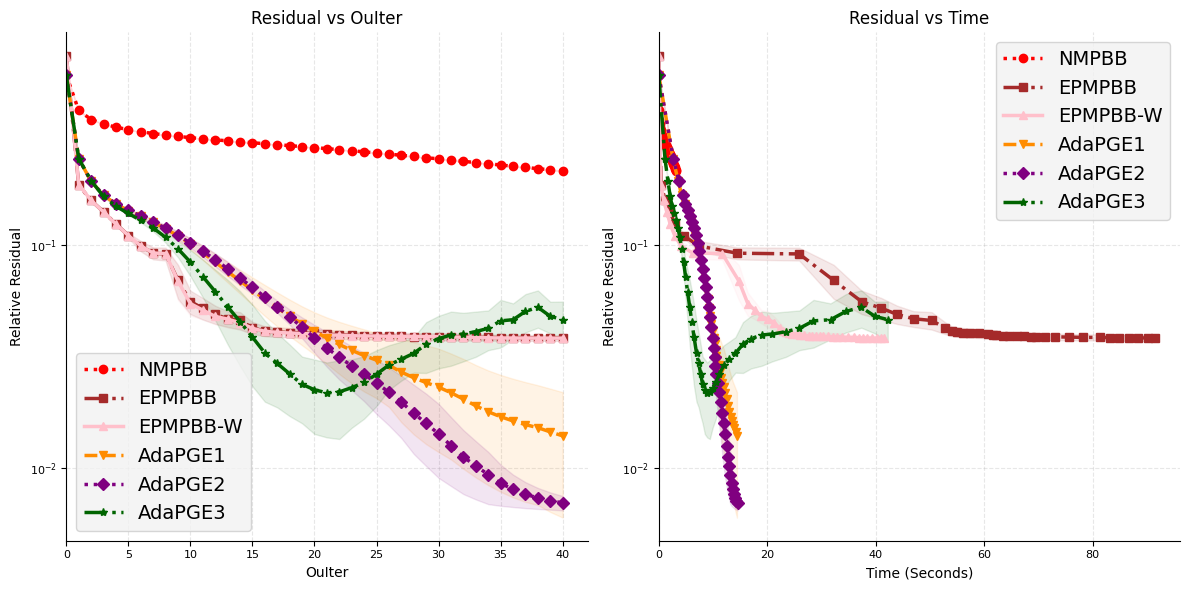

In [3]:
import numpy as np
import time
import matplotlib.pyplot as plt
from numba import njit
from statistics import mean, median
from scipy.interpolate import interp1d
from plot_stuffs import perf_plot

def rel_residual(V, W, H):
    return np.linalg.norm(V - W @ H, 'fro') / np.linalg.norm(V, 'fro')

def compute_condition_number(B, C, mu=1e-8):
    """
    Compute the maximum condition number of the Hessian matrices for the
    two NMF subproblems (B-block and C-block).
    Returns: max_cond, cond_B, cond_C
    """
    free_indx=np.where(np.linalg.norm(B, axis=0) > 1e-12)[0]
    # B = B[:, free_indx] # i didn't use this because it will change the shape of B and C, which may not be desirable
    # Hessian for B-block: C^T C 
    H_B = C.T@C 
    H_res= H_B[np.ix_(free_indx, free_indx)]
    # filter out near-zero eigenvalues 
    cond_B =np.linalg.cond(H_res) if H_res.size > 0 else np.inf

    # Hessian for C-block: B^T B 
    H_C = B.T@B 
    H_res_C= H_C[np.ix_(free_indx, free_indx)]
    cond_C =np.linalg.cond(H_res_C) if H_res_C.size > 0 else np.inf

    max_cond = max(cond_B, cond_C)
    q = ((max_cond - 1) / (max_cond + 1))

    # sqrt_kappa = np.sqrt(kappa)
    # q = ((sqrt_kappa - 1) / (sqrt_kappa + 1)) ** 2

    return q, max_cond


def sci(x, prec=2):
    if x == 0:
        return "0"
    exp = int(f"{x:e}".split("e")[1])
    man = x / (10 ** exp)
    return f"{man:.{prec}f} x 10^{{{exp}}}"

methods = [
            # ("HALS", HALS.solve_W_HALS),
        # ("NeNMF", NeNMF.solve_OGM),
        # ("QRPBB", QRPBB.solve_W_QRPBB),
        # ("QRPBB-N", QRPBB_N.solve_W_QRPBB),
        # ("ANPBB", ANPBB.solve_W_ANPBB),
        ("NMPBB", solve_W_NMPBB),
        ("EPMPBB", EMPBB.solve_EPMPBB),
        ("EPMPBB-W", EMPBBW.solve_EPMPBBW),
        ("AdaPGE1", AdaPGE1.solve_W_AdaPGE1),
        ("AdaPGE2", AdaPGE2.solve_W_AdaPGE2),
        ("AdaPGE3", AdaPGE3.solve_W_AdaPGE3),
    ]
output_dir="FIGs-Final2" #.  Failure-->divergence mode: (250,500,30),(2000,500,40),(500,300,40); but let's try (1000,2000,50), 
MAX_OUTER =40
MAX_INNER=500
MIN_INNER=1e-5
## FINAL VERSION!
# LIST_PROB=[(60,30,5),(100,60,15),(150,250,20),(250,100,10),(300,100,25),(500,150,35),(1000,600,40),(1000,2000,45)]
LIST_PROB=[(1000,600,40),(1000,2000,45)] # large scale problems, the NMPBB algo. should be modified to handle divergence
# --- Main Experiment Configuration ---
if __name__ == "__main__":    
    for prob in LIST_PROB:
        NUM_TRIALS =5
        # Storage structures
        histories = {name: {"obj": [], "time": [], "res": [], "final_time": [], "final_res": [], \
                            "final_proj": [], "inner_iter": [], "cond": [], "theo_res": [], "q": []} for name, _ in methods}
        
        print(f"Running {NUM_TRIALS} trials for each method...\n")
        m,n,r= prob
        for trial in range(NUM_TRIALS):
            # Set seed for the trial
            np.random.seed(trial * 100 + 1)
            print(f"Trial {trial+1}/{NUM_TRIALS}", end="\r")
            W_true = np.maximum(0, np.random.randn(m, r))
            H_true = np.maximum(0, np.random.randn(r, n))
            V = W_true@H_true + 0.05*np.random.randn(m, n)
            V = np.maximum(0, V)

            for name, func in methods:
                print(f"  Running {name}...", end="\r")
                # Capture the new return value: res_hist
                if name in ["EPMPBB", "EPMPBB-W"]:
                    W, H, total_time,fina_proj,inner_it, obj_hist, res_hist, time_hist,proj_hist= \
                        solve_NMF_EPMPBB(V,r, func, max_outer=MAX_OUTER, inner_tol=MIN_INNER, inner_max=MAX_INNER)
                elif name == "NeNMF":
                    W, H, total_time, fina_proj, inner_it, obj_hist, res_hist, time_hist, proj_hist = \
                        solve_NMF_NeNMF(V,r,func, max_outer=MAX_OUTER, inner_tol=MIN_INNER, inner_max=MAX_INNER)
                # elif name in  ["AdaPGE1","AdaPGE2","AdaPGE3"]:
                #     W, H, total_time, fina_proj, inner_it, obj_hist, res_hist, time_hist, proj_hist = \
                #         solve_NMF_ANLS(V, r, func, max_outer=MAX_OUTER, inner_tol=MIN_INNER, inner_max=MAX_INNER)
                else:
                    # W, H, total_time,fina_proj,inner_it, obj_hist, res_hist, time_hist,proj_hist=solve_NMF_ANLS(V, \
                    #             r, func, max_outer=MAX_OUTER, inner_tol=1e-4, inner_max=MAX_INNER)
                    W, H, total_time, fina_proj, inner_it, obj_hist, res_hist, time_hist, proj_hist = \
                        solve_NMF_ANLS2(V, r, func, max_outer=MAX_OUTER, inner_tol=MIN_INNER, inner_max=MAX_INNER)

                # Compute condition number
                
                # Compute theoretical BCD rate
                # q, max_cond = compute_theoretical_cond_plus_rate(W, H, mu=1e-8)
                q, max_cond=compute_condition_number(W, H, mu=1e-8)  # Use the new function to compute q and max_cond
                # Generate theoretical residual curve
                initial_res = res_hist[0]
                num_outer = len(res_hist)-1
                theo_res = [initial_res*(q**k) for k in range(num_outer+1)]

                # Store res_histories
                histories[name]["obj"].append(obj_hist)
                histories[name]["res"].append(res_hist)      # <--- NEW
                histories[name]["time"].append(time_hist)
                histories[name]["final_time"].append(total_time)
                histories[name]["final_proj"].append(fina_proj)
                histories[name]["inner_iter"].append(inner_it)

                histories[name]["final_res"].append(rel_residual(V, W, H))
                histories[name]["cond"].append(max_cond)
                histories[name]["theo_res"].append(theo_res)
                histories[name]["q"].append(q)


                del W, H, total_time,fina_proj,inner_it, obj_hist, res_hist, time_hist,proj_hist
        print("Trials complete. Processing results...\n")

        labels = ["Obj", "Res", "Proj", "InIter"]
        w =16

        # ---- Statistics Table ----
        print("=" * 200)

        # metric names centered
        print(f"{'':<12} " + f" | {'Time':^{15}} | " + " | ".join(f"{l:^{w}}" for l in labels) 
              + f" | {'Cond':^32}" + f" | {'Theo Rate (q)':^15}")
        # short line under each metric
        print(f"{'Method':<12} " + f" | {'-'*len('Time'):^{15}} | " + " | ".join(f"{'-'*len(l):^{w}}" for l in labels) 
              + f" | {'-'*5:^32}" + f" | {'-'*14:^15}")
        # μ±σ row
        print(f"{'':<12} " + f" | {'μ±σ':^{15}} | " + " | ".join(f"{'μ±σ':^{w}}" for l in labels) 
              + f" | {'μ±σ':^32}" + f" | {'μ±σ':^15}")

        print("=" * 200)

        for name, _ in methods:
            t_mean = mean(histories[name]["final_time"])
            t_med = median(histories[name]["final_time"])
            t_std = np.std(histories[name]["final_time"])

            objs = [h[-1] for h in histories[name]["obj"]]
            o_mean = mean(objs); o_med = median(objs); o_std = np.std(objs)
            r_mean = mean(histories[name]["final_res"]); r_med = median(histories[name]["final_res"]); r_std = np.std(histories[name]["final_res"])
            pr_mean = mean(histories[name]["final_proj"]); pr_med = median(histories[name]["final_proj"]); pr_std = np.std(histories[name]["final_proj"])
            sum_iter = [sum(it) for it in histories[name]["inner_iter"]]
            it_mean = mean(sum_iter); it_med = median(sum_iter); it_std = np.std(sum_iter)
            cond_mean = mean(histories[name]["cond"]); cond_med = median(histories[name]["cond"]); cond_std = np.std(histories[name]["cond"])
            q_mean = mean(histories[name]["q"]); q_med = median(histories[name]["q"]); q_std = np.std(histories[name]["q"])

            print(f"{name:<12} | {t_mean:<6.4f} \u00b1 {t_std:<6.4f} "
                  f"| {o_mean:<8.4f} \u00b1 {o_std:<8.4f} "
                  f"| {r_mean:<6.4f} \u00b1 {r_std:<6.4f} "
                  f"| {pr_mean:<6.4f} \u00b1 {pr_std:<6.4f} "
                  f"| {it_mean:<6.2f} \u00b1 {it_std:<6.2f} "
                  f"| {sci(cond_mean)} \u00b1 {sci(cond_std)} "
                  f"| {q_mean:<6.2f} \u00b1 {q_std:<6.2f}")
        print("=" * 200)

        perf_plot(histories,methods, prob,output_dir)

## Perform motivating experiments

In [1]:

import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
from Algos.AlgosPaper import NMPBB, QRPBB, AdaPGE1,AdaPGE2,AdaPGE3,AdaPGE4,\
          NeNMF,ANPBB, EMPBB, EMPBBW
from NMF_ANLS import solve_NMF_ANLS, solve_NMF_EPMPBB, solve_NMF_NeNMF,\
        solve_NMF_ANLS2

from plot_stuffs import perf_plot_convtest


Running 5 trials for each method...

Trials complete. Processing results...

Method          | Time (Mean)  | Time (Median) | Obj (Mean) | Obj (Median) | Res (Mean) | Res (Median) | Proj (Mean) | Proj (Median) | InIter (Mean) | InIter (Median)
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
NMPBB           | 16.1549      | 19.8870      | nan         | 147.092251  | nan          | 0.009040     | nan          | 57.619727    | 81115.20     | 85882.00    


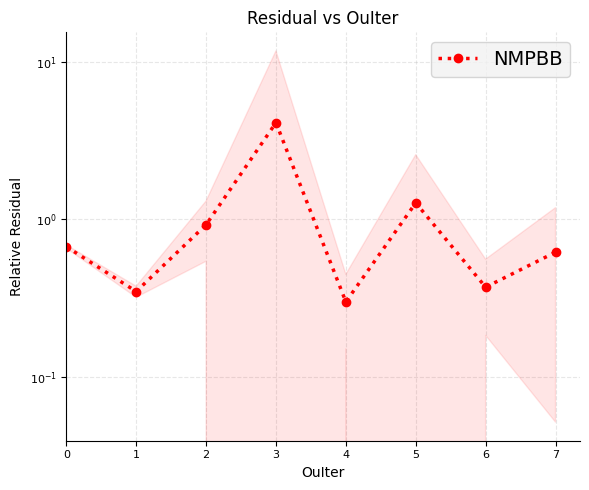

Running 5 trials for each method...

Trials complete. Processing results...

Method          | Time (Mean)  | Time (Median) | Obj (Mean) | Obj (Median) | Res (Mean) | Res (Median) | Proj (Mean) | Proj (Median) | InIter (Mean) | InIter (Median)
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
NMPBB           | 37.1053      | 31.9885      | 621421.698042 | 313798.373433 | 0.284278     | 0.294798     | 108582949089.512848 | 2754.012029  | 185465.00    | 182985.00   


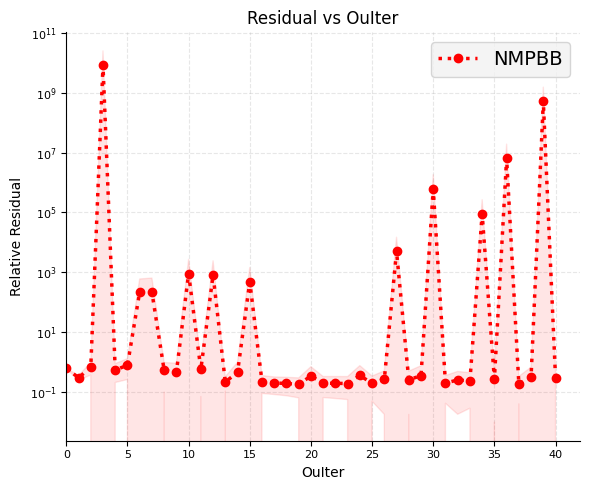

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
from numba import njit
from statistics import mean, median
from scipy.interpolate import interp1d
from plot_stuffs import perf_plot

def rel_residual(V, W, H):
    return np.linalg.norm(V - W @ H, 'fro') / np.linalg.norm(V, 'fro')

methods = [
            # ("HALS", HALS.solve_W_HALS),
        # ("NeNMF", NeNMF.solve_OGM),
        # ("QRPBB", QRPBB.solve_W_QRPBB),
        # ("QRPBB-N", QRPBB_N.solve_W_QRPBB),
        # ("ANPBB", ANPBB.solve_W_ANPBB),
        ("NMPBB", NMPBB.solve_W_NMPBB),
        # ("EPMPBB", EMPBB.solve_EPMPBB),
        # ("EPMPBB-W", EMPBBW.solve_EPMPBBW),
        # ("AdaPGE1", AdaPGE1.solve_W_AdaPGE1),
        # ("AdaPGE2", AdaPGE2.solve_W_AdaPGE2),
        # ("AdaPGE3", AdaPGE3.solve_W_AdaPGE3),
        # ("AdaPGE4", AdaPGE4.solve_W_AdaPGE4),
    ]
output_dir="FIGsNew" #.  Failure-->divergence mode: (250,500,30),(2000,500,40); but let's try (1000,2000,50), 
MAX_OUTER =40
MAX_INNER=500
MIN_INNER=1e-5
# LIST_PROB=[(60,30,5),(100,60,15),(150,250,20),(250,100,10),(300,100,25),(250,500,30),(500,150,40),(500,300,40),(1000,600,50),(2000,500,40)]
LIST_PROB=[(250,500,30),(500,300,40)]
# --- Main Experiment Configuration ---
if __name__ == "__main__":    
    for prob in LIST_PROB:
        NUM_TRIALS=5
        # Storage structures
        histories = {name: {"obj": [], "time": [], "res": [], "final_time": [], "final_res": [], \
                            "final_proj": [], "inner_iter": []} for name, _ in methods}
        
        print(f"Running {NUM_TRIALS} trials for each method...\n")
        m,n,r= prob
        for trial in range(NUM_TRIALS):
            # Set seed for the trial
            np.random.seed(trial * 100 + 1)
            print(f"Trial {trial+1}/{NUM_TRIALS}", end="\r")
            W_true = np.maximum(0, np.random.randn(m, r))
            H_true = np.maximum(0, np.random.randn(r, n))
            V = W_true@H_true + 0.05*np.random.randn(m, n)
            V = np.maximum(0, V)

            for name, func in methods:
                print(f"  Running {name}...", end="\r")
                # Capture the new return value: res_hist
                if name in ["EPMPBB", "EPMPBB-W"]:
                    W, H, total_time,fina_proj,inner_it, obj_hist, res_hist, time_hist,proj_hist=solve_NMF_EPMPBB(V, \
                                r, func, max_outer=MAX_OUTER, inner_tol=MIN_INNER, inner_max=MAX_INNER)
                elif name == "NeNMF":
                    W, H, total_time, fina_proj, inner_it, obj_hist, res_hist, time_hist, proj_hist = \
                        solve_NMF_NeNMF(V, r,func, max_outer=MAX_OUTER, inner_tol=MIN_INNER, inner_max=MAX_INNER)
                # elif name in  ["AdaPGE1","AdaPGE2","AdaPGE3"]:
                #     W, H, total_time, fina_proj, inner_it, obj_hist, res_hist, time_hist, proj_hist = \
                #         solve_NMF_ANLS(V, r, func, max_outer=MAX_OUTER, inner_tol=MIN_INNER, inner_max=MAX_INNER)
                else:
                    # W, H, total_time,fina_proj,inner_it, obj_hist, res_hist, time_hist,proj_hist=solve_NMF_ANLS(V, \
                    #             r, func, max_outer=MAX_OUTER, inner_tol=1e-4, inner_max=MAX_INNER)
                    W, H, total_time, fina_proj, inner_it, obj_hist, res_hist, time_hist, proj_hist = \
                        solve_NMF_ANLS2(V, r, func, max_outer=MAX_OUTER, inner_tol=MIN_INNER, inner_max=MAX_INNER)
                    
                # Store res_histories
                histories[name]["obj"].append(obj_hist)
                histories[name]["res"].append(res_hist)      # <--- NEW
                histories[name]["time"].append(time_hist)
                histories[name]["final_time"].append(total_time)
                histories[name]["final_proj"].append(fina_proj)
                histories[name]["inner_iter"].append(inner_it)

                histories[name]["final_res"].append(rel_residual(V, W, H))
                
                del W, H, total_time,fina_proj,inner_it, obj_hist, res_hist, time_hist,proj_hist
        print("Trials complete. Processing results...\n")

        # --- Mean/Median Statistics Table ---
        print("=" * 200)
        print(f"{'Method':<15} | {'Time (Mean)':<12} | {'Time (Median)':<12} "
            f"| {'Obj (Mean)':<10} | {'Obj (Median)':<10} "
            f"| {'Res (Mean)':<10} | {'Res (Median)':<10} "
            f"| {'Proj (Mean)':<10} | {'Proj (Median)':<10} | {'InIter (Mean)':<10} | {'InIter (Median)':<10}")
        print("-" * 200)

        for name, _ in methods:
            t_mean = mean(histories[name]["final_time"])
            t_med = median(histories[name]["final_time"])
            
            # Get objective at final outer iteration (last element of obj_hist)
            objs = [obj_hist[-1] for obj_hist in histories[name]["obj"]]
            o_mean = mean(objs)
            o_med = median(objs)
            
            r_mean = mean(histories[name]["final_res"])
            r_med = median(histories[name]["final_res"])
            
            pr_mean = mean(histories[name]["final_proj"])
            pr_med = median(histories[name]["final_proj"])

            sum_iter = [sum(total) for total in histories[name]["inner_iter"]]
            it_mean = mean(sum_iter)
            it_med = median(sum_iter)

            print(f"{name:<15} | {t_mean:<12.4f} | {t_med:<12.4f} "
                    f"| {o_mean:<11.6f} | {o_med:<11.6f} "
                    f"| {r_mean:<12.6f} | {r_med:<12.6f} "
                    f"| {pr_mean:<12.6f} | {pr_med:<12.6f} | {it_mean:<12.2f} | {it_med:<12.2f}")
        print("="*200)
        # ploting time!
        # perf_plot(histories,methods, prob,output_dir)
        perf_plot_convtest(histories,methods, prob,output_dir)